# 01. Grid and county keys

**Goal:** build the empty skeleton of the modelling table: one row for every county and every month from January 2000 to December 2025. Every other dataset is joined onto this skeleton later, so it has to be right.

**Inputs**
- `data/reference/kenya_county_crosswalk.csv` (the county code table)
- `data/reference/county_adjacency.csv` (which counties touch which)
- `data/interim/grid.csv` (the pipeline's grid, used only as a cross-check at the end)

**Outputs**
- `data/interim/nb_grid.csv`: `pcode, county, year, month, season, month_sin, month_cos` (14,664 rows)

The reference for every step is the pipeline in `src/data/` (stage `01_grid.py`).

In [1]:
# import the libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. The county code table (crosswalk)

Different datasets name the 47 counties in different ways. The crosswalk is the one table that translates between them. We read it with `dtype=str` because some codes start with zero.

In [2]:
# load the crosswalk, reading every column as text
cw = pd.read_csv("../../data/reference/kenya_county_crosswalk.csv", dtype=str)
print(cw.shape)
cw.head(8)

(47, 5)


,county,knbs_code,pcode,desinventar_code,desinventar_name
0,Mombasa,1,KE001,28,MOMBASA
1,Kwale,2,KE002,19,KWALE
2,Kilifi,3,KE003,14,KILIFI
3,Tana River,4,KE004,40,TANA-RIVER
4,Lamu,5,KE005,21,LAMU
5,Taita-Taveta,6,KE006,39,TAITA-TAVETA
6,Garissa,7,KE007,06,GARISSA
7,Wajir,8,KE008,46,WAJIR


**Observation:** The crosswalk has 47 rows and 5 columns, one row per county. Mombasa is `KE001` / census number 1 / DesInventar code `28`, but Garissa is `KE007` / 7 / `06`. The DesInventar numbers follow an alphabetical list, so they do not match the official order.

**The `dtype=str` trap.** If pandas is allowed to guess, it turns the DesInventar code `'06'` into the number `6`. Then it no longer matches the `'06'` used by other files.

In [3]:
# read the same file again, letting pandas guess the types
cw_guess = pd.read_csv("../../data/reference/kenya_county_crosswalk.csv")
print("guessed dtype of desinventar_code:", cw_guess["desinventar_code"].dtype)
print("as text :", cw.loc[cw["county"] == "Isiolo", "desinventar_code"].tolist())
print("guessed :", cw_guess.loc[cw_guess["county"] == "Isiolo", "desinventar_code"].tolist())

guessed dtype of desinventar_code: int64
as text : ['08']
guessed : [8]


**Observation:** When pandas guesses the type, `desinventar_code` becomes `int64` and Isiolo's `'08'` turns into the number `8`. Other files store it as the text `'08'`, so a merge on this column would silently find no match for Isiolo.

In [4]:
# show how many codes would fail to match a text code like '08' after guessing
as_text = cw["desinventar_code"].tolist()
as_number = cw_guess["desinventar_code"].astype(str).tolist()
n_broken = sum(1 for a, b in zip(as_text, as_number) if a != b)
print("codes that change when read as numbers:", n_broken, "of", len(as_text))
print("examples:", [(a, b) for a, b in zip(as_text, as_number) if a != b][:5])

codes that change when read as numbers: 9 of 47
examples: [('06', '6'), ('08', '8'), ('05', '5'), ('01', '1'), ('09', '9')]


**Observation:** 9 of the 47 codes change when read as numbers (`'06'` -> `'6'`, `'08'` -> `'8'`, `'05'`, `'01'`, `'09'` and four more). These are exactly the codes below 10. We therefore read every code column with `dtype=str` in all notebooks.

**Why `pcode` is the key.** `pcode` (`KE001` to `KE047`) is the official OCHA/HDX county code. It is the code used by the WFP rainfall and NDVI files and by the boundary files, and it is the same text in every file. The other codes are traps:
- `knbs_code` is the census number 1 to 47 (Nairobi is 47).
- `desinventar_code` is an alphabetical number used by DesInventar, the Global Flood Database and the old Earth Engine exports (Nairobi is 30, not 47).

Whenever a file uses a different code, we convert it to `pcode` through this table and never match on county names.

In [5]:
# show Nairobi under each of its codes
cw[cw["county"] == "Nairobi"]

,county,knbs_code,pcode,desinventar_code,desinventar_name
46,Nairobi,47,KE047,30,NAIROBI


**Observation:** Nairobi has three different numbers: `pcode` `KE047`, census number 47 and DesInventar code `30`. Mixing these up would attach Nairobi's floods to the wrong county (DesInventar code 47 belongs to another county). This is why every file is converted to `pcode` through the crosswalk.

In [6]:
# check the crosswalk: 47 rows, unique codes, pcodes KE001 to KE047
print("rows:", len(cw))
print("unique pcodes:", cw["pcode"].nunique())
print("unique desinventar codes:", cw["desinventar_code"].nunique())
expected = ["KE" + str(i).zfill(3) for i in range(1, 48)]
print("pcodes are exactly KE001..KE047:", sorted(cw["pcode"].tolist()) == expected)
print("missing values:", int(cw.isna().sum().sum()))

rows: 47
unique pcodes: 47
unique desinventar codes: 47
pcodes are exactly KE001..KE047: True
missing values: 0


**Observation:** The crosswalk is clean: 47 rows, 47 unique `pcode` values that are exactly `KE001` to `KE047`, 47 unique DesInventar codes and 0 missing values. It is safe to use as the single source of county identity.

As a worked example of the conversion, the Global Flood Database file (used later in notebook 04) only has the DesInventar code. We map its codes to `pcode` with the crosswalk.

In [7]:
# map the Global Flood Database county codes to pcode
gfd = pd.read_csv("../../data/raw/flood_labels/global_flood_database/kenya_gfd_county_floods.csv", dtype={"county_code": str})
code_to_pcode = dict(zip(cw["desinventar_code"], cw["pcode"]))
gfd["pcode"] = gfd["county_code"].map(code_to_pcode)
print("GFD rows:", len(gfd), "| distinct county codes:", gfd["county_code"].nunique())
print("rows that did not map:", int(gfd["pcode"].isna().sum()))
gfd[gfd["county_name"] == "NAIROBI"][["county_code", "county_name", "pcode"]].drop_duplicates()

GFD rows: 358 | distinct county codes: 42
rows that did not map: 0


,county_code,county_name,pcode
44,30,NAIROBI,KE047


**Observation:** All 358 Global Flood Database rows mapped to a `pcode` (0 unmapped), using 42 distinct county codes. Code `'30'` becomes `KE047`, which is Nairobi, as expected. So 5 counties never appear in this satellite flood file.

## 2. The empty grid: 47 counties x 312 months

A cross join pairs every county with every (year, month). 47 counties x 26 years x 12 months should give 14,664 rows.

In [8]:
# make a table with every year and month from 2000 to 2025
years = pd.DataFrame({"year": range(2000, 2026)})
months = pd.DataFrame({"month": range(1, 13)})
year_month = years.merge(months, how="cross")
print(year_month.shape)
year_month.head(3)

(312, 2)


,year,month
0,2000,1
1,2000,2
2,2000,3


**Observation:** There are 312 distinct year-month pairs (26 years x 12 months), starting at January 2000.

In [9]:
# cross join the counties with the months to make the grid
grid = cw[["pcode", "county"]].merge(year_month, how="cross")
grid = grid.sort_values(["pcode", "year", "month"], ignore_index=True)
print(grid.shape, "=", 47, "x", len(year_month))
grid.head(3)

(14664, 4) = 47 x 312


,pcode,county,year,month
0,KE001,Mombasa,2000,1
1,KE001,Mombasa,2000,2
2,KE001,Mombasa,2000,3


**Observation:** The cross join gives 14,664 rows, which is 47 counties x 312 months. The first rows are Mombasa (`KE001`) from January 2000, sorted by county, then year, then month.

**Season.** East Africa has two rainy seasons, the long rains (March to May) and the short rains (October to December). A model can use the season as a simple label: JF (dry), MAM (long rains), JJAS (cool and drier), OND (short rains).

In [10]:
# add the season with a month-to-season dictionary
season_of = {1: "JF", 2: "JF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJAS", 7: "JJAS", 8: "JJAS", 9: "JJAS",
             10: "OND", 11: "OND", 12: "OND"}
grid["season"] = grid["month"].map(season_of)
grid["season"].value_counts()

season
JJAS    4888
MAM     3666
OND     3666
JF      2444
Name: count, dtype: int64

**Observation:** The seasons have 2,444 rows for JF (2 months x 47 counties x 26 years), 3,666 each for MAM and OND (3 months) and 4,888 for JJAS (4 months). The counts match the number of months in each season.

**Month as a circle.** The month number treats December (12) and January (1) as far apart, but they are neighbours in the calendar. Sine and cosine put the 12 months on a circle, so December and January end up next to each other. We keep both because one alone cannot tell two months apart (sine is the same for March and June).

In [11]:
# add month_sin and month_cos
grid["month_sin"] = np.sin(2 * np.pi * grid["month"] / 12)
grid["month_cos"] = np.cos(2 * np.pi * grid["month"] / 12)
grid[(grid["county"] == "Kisumu") & (grid["year"] == 2024)].head(12)

,pcode,county,year,month,season,month_sin,month_cos
13080,KE042,Kisumu,2024,1,JF,5.000000e-01,8.660254e-01
13081,KE042,Kisumu,2024,2,JF,8.660254e-01,5.000000e-01
13082,KE042,Kisumu,2024,3,MAM,1.000000e+00,6.123234e-17
13083,KE042,Kisumu,2024,4,MAM,8.660254e-01,-5.000000e-01
13084,KE042,Kisumu,2024,5,MAM,5.000000e-01,-8.660254e-01
13085,KE042,Kisumu,2024,6,JJAS,1.224647e-16,-1.000000e+00
13086,KE042,Kisumu,2024,7,JJAS,-5.000000e-01,-8.660254e-01
13087,KE042,Kisumu,2024,8,JJAS,-8.660254e-01,-5.000000e-01
13088,KE042,Kisumu,2024,9,JJAS,-1.000000e+00,-1.836970e-16
13089,KE042,Kisumu,2024,10,OND,-8.660254e-01,5.000000e-01


**Observation:** For Kisumu 2024, April has `month_sin` 0.866 and `month_cos` -0.5, the values used later in the worked example. The sine of month 6 is 1.2e-16 and the cosine of month 3 is 6.1e-17, which are 0 apart from floating-point rounding.

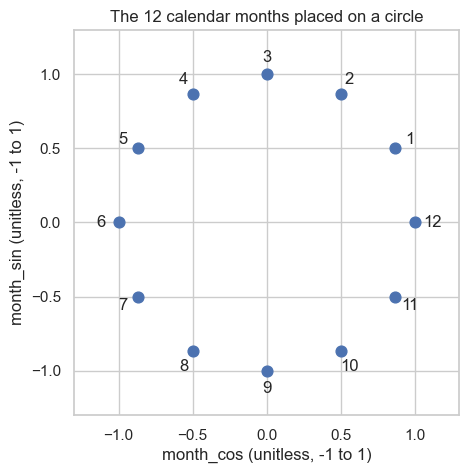

In [12]:
# draw the 12 months on the circle
one_year = grid[(grid["county"] == "Kisumu") & (grid["year"] == 2024)]
plt.figure(figsize=(5, 5))
plt.scatter(one_year["month_cos"], one_year["month_sin"], s=60)
for m, x, y in zip(one_year["month"], one_year["month_cos"], one_year["month_sin"]):
    plt.text(x * 1.12, y * 1.12, str(m), ha="center", va="center")
plt.title("The 12 calendar months placed on a circle")
plt.xlabel("month_cos (unitless, -1 to 1)")
plt.ylabel("month_sin (unitless, -1 to 1)")
plt.xlim(-1.3, 1.3)
plt.ylim(-1.3, 1.3)
plt.gca().set_aspect("equal")
plt.show()

**Observation:** The 12 months sit evenly around the circle. Month 12 (December) is next to month 1 (January), while month 6 and month 12 are at opposite sides. This is the reason for using sine and cosine instead of the month number.

### Sanity checks on the grid

In [13]:
# check 1: row count and duplicate keys
print("rows:", len(grid))
print("duplicate (pcode, year, month) keys:", int(grid.duplicated(["pcode", "year", "month"]).sum()))

rows: 14664
duplicate (pcode, year, month) keys: 0


**Observation:** The grid has 14,664 rows and 0 duplicated (`pcode`, `year`, `month`) keys, so later left merges cannot create extra rows.

In [14]:
# check 2: months per county, counties per month, year range
print("months per county (min, max):", grid.groupby("pcode").size().min(), grid.groupby("pcode").size().max())
print("counties per (year, month) (min, max):", grid.groupby(["year", "month"]).size().min(), grid.groupby(["year", "month"]).size().max())
print("years:", grid["year"].min(), "to", grid["year"].max())
print("first row month:", grid["year"].iloc[0], grid["month"].iloc[0], "| last row month:", grid["year"].iloc[-1], grid["month"].iloc[-1])

months per county (min, max): 312 312
counties per (year, month) (min, max): 47 47
years: 2000 to 2025
first row month: 2000 1 | last row month: 2025 12


**Observation:** Every county has exactly 312 months and every month has exactly 47 counties. The first row is January 2000 and the last row is December 2025, so there are no gaps or missing counties.

In [15]:
# check 3: no missing values and the expected value ranges
print("missing values:", int(grid.isna().sum().sum()))
print("month range:", grid["month"].min(), "to", grid["month"].max())
print("month_sin range:", round(grid["month_sin"].min(), 3), "to", round(grid["month_sin"].max(), 3))
print("seasons:", sorted(grid["season"].unique()))

missing values: 0
month range: 1 to 12
month_sin range: -1.0 to 1.0
seasons: ['JF', 'JJAS', 'MAM', 'OND']


**Observation:** There are 0 missing values. `month` runs from 1 to 12, `month_sin` runs from -1.0 to 1.0, and the four seasons are `JF`, `JJAS`, `MAM` and `OND`.

In [16]:
# check 4: compare with the grid built by the pipeline (data/interim/grid.csv)
pipe = pd.read_csv("../../data/interim/grid.csv", dtype={"pcode": str})
print("same shape:", pipe.shape == grid.shape)
print("same columns:", list(pipe.columns) == list(grid.columns))
same_keys = (pipe[["pcode", "year", "month"]].values == grid[["pcode", "year", "month"]].values).all()
print("same row order of keys:", bool(same_keys))
print("largest difference in month_sin / month_cos:", float(np.abs(pipe["month_sin"] - grid["month_sin"]).max()), float(np.abs(pipe["month_cos"] - grid["month_cos"]).max()))

same shape: True
same columns: True
same row order of keys: True
largest difference in month_sin / month_cos: 0.0 0.0


**Observation:** The notebook grid is identical to the pipeline's `data/interim/grid.csv`: same shape, same columns, same row order, and a maximum difference of 0.0 in `month_sin` and `month_cos`.

## 3. County boundaries (explained in text only)

The boundaries are not rebuilt in this notebook, because that needs shapefile tools and is done by `src/data/00_boundaries.py`. The decisions behind it:

- **Source:** OCHA COD-AB admin level 1 (the 47 counties). It is the official boundary set, keyed by `pcode`.
- **Lakes removed:** the polygons include Lake Victoria, Lake Turkana and Lake Natron. Water has no rain gauge, land cover or soil, and would make counties like Homa Bay look much larger than their land. The lakes are cut out using the Natural Earth 10 m lake outlines, so every satellite feature is averaged over land only.
- **Check:** the land-only areas are compared with the official KNBS land areas. The median ratio is 1.000 (smallest 0.963, largest 1.062) and the total is 580,578 km2 against 580,876 km2 officially.

Area removed from each county (from the build log, `data/interim/build_log.txt`):

| lake | county | area cut out (km2) |
|---|---|---|
| Lake Turkana | Marsabit | 4,920 |
| Lake Turkana | Turkana | 2,322 |
| Lake Victoria | Homa Bay | 1,514 |
| Lake Victoria | Siaya | 1,002 |
| Lake Victoria | Kisumu | 584 |
| Lake Victoria | Migori | 520 |
| Lake Victoria | Busia | 133 |
| Lake Turkana | Samburu | 2 |
| Lake Natron | Kajiado | 1 |

The land-only polygons are saved as `data/reference/kenya_counties.geojson` (used for neighbours and for the river-discharge cell lookup) and a version with the lakes left in is saved as `kenya_counties_full.geojson` (for maps only).

## 4. Which counties touch which (adjacency)

`neighbour_rain` (notebook 02) averages the rainfall of a county's neighbours. The pipeline finds the neighbours by checking which county polygons touch (with a tiny 0.001 degree buffer so that thin gaps between polygons do not hide a border). The result is saved in `county_adjacency.csv`. Here we only read it.

In [17]:
# load the adjacency pairs
adj = pd.read_csv("../../data/reference/county_adjacency.csv", dtype={"pcode": str, "neighbour_pcode": str})
print(adj.shape)
adj.head()

(244, 3)


,pcode,neighbour_pcode,approx_shared_border_km
0,KE001,KE002,21.3
1,KE001,KE003,25.2
2,KE002,KE001,21.3
3,KE002,KE006,130.1
4,KE002,KE003,102.5


**Observation:** The adjacency file has 244 rows, one for each directed pair of touching counties, with the shared border length in km (Mombasa-Kwale 21.3 km, Kwale-Taita-Taveta 130.1 km).

In [18]:
# check the pairs are symmetric (if A touches B then B touches A)
pairs = set(zip(adj["pcode"], adj["neighbour_pcode"]))
reverse_missing = [p for p in pairs if (p[1], p[0]) not in pairs]
print("directed pairs:", len(pairs), "| borders:", len(pairs) // 2)
print("pairs without a mirror:", len(reverse_missing))
print("counties with at least one neighbour:", adj["pcode"].nunique())

directed pairs: 244 | borders: 122
pairs without a mirror: 0
counties with at least one neighbour: 47


**Observation:** There are 244 directed pairs, which is 122 borders, and every pair has its mirror (0 pairs without a mirror). All 47 counties have at least one neighbour, so `neighbour_rain` can be calculated for every county.

In [19]:
# count the neighbours of each county
counts = adj.groupby("pcode").size().rename("n_neighbours").reset_index()
counts = counts.merge(cw[["pcode", "county"]], on="pcode").sort_values("n_neighbours", ascending=False)
print(counts["n_neighbours"].describe().round(2))
counts.head(10)

count    47.00
mean      5.19
std       1.84
min       1.00
25%       4.00
50%       5.00
75%       7.00
max       8.00
Name: n_neighbours, dtype: float64


,pcode,n_neighbours,county
14,KE015,8,Kitui
11,KE012,8,Meru
10,KE011,8,Isiolo
31,KE032,8,Nakuru
34,KE035,8,Kericho
29,KE030,8,Baringo
15,KE016,8,Machakos
18,KE019,7,Nyeri
30,KE031,7,Laikipia
33,KE034,7,Kajiado


**Observation:** Counties have between 1 and 8 neighbours, on average 5.19 (median 5). Seven counties have 8 neighbours (Kitui, Meru, Isiolo, Nakuru, Kericho, Baringo, Machakos). Mandera has only 1 neighbour, so its `neighbour_rain` equals the rain of a single county.

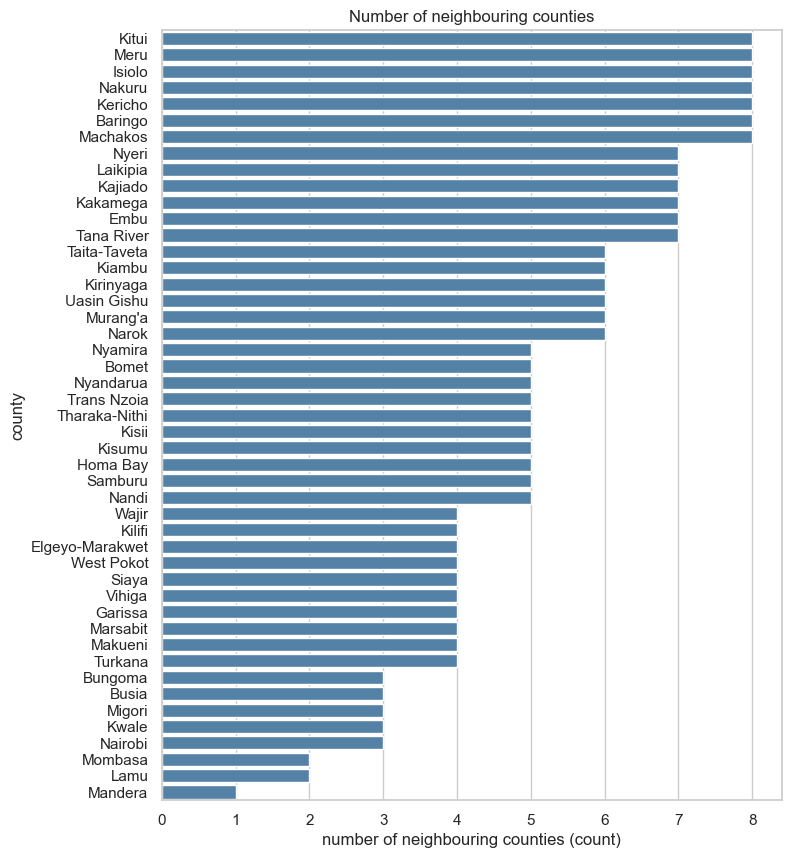

In [20]:
# plot the number of neighbours for every county
plt.figure(figsize=(8, 10))
sns.barplot(data=counts, y="county", x="n_neighbours", color="steelblue")
plt.title("Number of neighbouring counties")
plt.xlabel("number of neighbouring counties (count)")
plt.ylabel("county")
plt.show()

**Observation:** The bar chart shows the same picture: most counties have 4 to 6 neighbours, while the coastal and border counties have the fewest (Mandera 1, Mombasa 2, Lamu 2). Counties with few neighbours get a noisier `neighbour_rain`.

## 5. Save the grid

In [21]:
# save the grid for the next notebooks
os.makedirs("../../data/interim", exist_ok=True)
grid.to_csv("../../data/interim/nb_grid.csv", index=False)
print("saved", grid.shape, "to data/interim/nb_grid.csv")

saved (14664, 7) to data/interim/nb_grid.csv


**Observation:** The grid (14,664 rows x 7 columns: `pcode`, `county`, `year`, `month`, `season`, `month_sin`, `month_cos`) was saved as `data/interim/nb_grid.csv` for notebooks 02 to 04.

## Summary

- The crosswalk holds 47 counties. `pcode` is the join key because it is the code in the rainfall, NDVI and boundary files. Reading codes without `dtype=str` silently breaks the DesInventar codes.
- The grid has 47 counties x 312 months = 14,664 rows with no duplicate keys, plus `season`, `month_sin` and `month_cos`. It matches the pipeline's grid exactly.
- Boundaries are COD-AB land-only polygons (lakes removed). Adjacency has 244 directed pairs (122 borders) and every county has at least one neighbour.
- Next: notebook 02 adds rainfall, neighbour rainfall, NDVI, ONI and DMI to this grid.